<a href="https://colab.research.google.com/github/Rangan-Roy01/localrepo/blob/main/Mutiple_Linreg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df=pd.read_csv("/content/Salary Data.csv")

In [3]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [5]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [6]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,2
Job Title,2
Years of Experience,2
Salary,2


In [9]:
df[df.isnull().any(axis=1)]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df.dropna(inplace=True)

In [11]:
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [12]:
df.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [16]:
df_encoded=pd.get_dummies(df,columns=['Gender'],drop_first=True,dtype=int)

In [17]:
df_encoded.head()

,Age,Education Level,Job Title,Years of Experience,Salary,Gender_Male
0,32.0,Bachelor's,Software Engineer,5.0,90000.0,1
1,28.0,Master's,Data Analyst,3.0,65000.0,0
2,45.0,PhD,Senior Manager,15.0,150000.0,1
3,36.0,Bachelor's,Sales Associate,7.0,60000.0,0
4,52.0,Master's,Director,20.0,200000.0,1


In [18]:
df['Education Level'].unique()

array(["Bachelor's", "Master's", 'PhD'], dtype=object)

In [20]:
df_encoded['Education Level']=df_encoded['Education Level'].map({"Bachelor's":0,"Master's":1,'PhD':2})

In [21]:
df_encoded.head()

,Age,Education Level,Job Title,Years of Experience,Salary,Gender_Male
0,32.0,0,Software Engineer,5.0,90000.0,1
1,28.0,1,Data Analyst,3.0,65000.0,0
2,45.0,2,Senior Manager,15.0,150000.0,1
3,36.0,0,Sales Associate,7.0,60000.0,0
4,52.0,1,Director,20.0,200000.0,1


In [23]:
df_encoded['Job Title'].value_counts()

,count
Job Title,
Director of Marketing,12
Director of Operations,11
Senior Business Analyst,10
Senior Marketing Manager,9
Senior Marketing Analyst,9
...,...
Junior Social Media Specialist,1
Junior Operations Coordinator,1
Senior HR Specialist,1


In [24]:
df_encoded.drop('Job Title',axis=1,inplace=True)

In [25]:
df_encoded.head()

,Age,Education Level,Years of Experience,Salary,Gender_Male
0,32.0,0,5.0,90000.0,1
1,28.0,1,3.0,65000.0,0
2,45.0,2,15.0,150000.0,1
3,36.0,0,7.0,60000.0,0
4,52.0,1,20.0,200000.0,1


In [26]:
X=df_encoded[['Age','Education Level','Gender_Male','Years of Experience']]
y=df_encoded['Salary']

In [27]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [28]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((298, 4), (75, 4), (298,), (75,))

In [29]:
X_train

,Age,Education Level,Gender_Male,Years of Experience
193,34.0,0,1,7.0
75,37.0,0,1,10.0
84,29.0,0,0,2.0
363,33.0,0,1,5.0
16,33.0,1,0,7.0
...,...,...,...,...
71,39.0,0,0,11.0
106,30.0,0,0,3.0
272,37.0,0,1,8.0
350,44.0,2,0,16.0


In [30]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [31]:
X_train_scaled

array([[-0.49634932, -0.72737895,  0.98666607, -0.46912258],
       [-0.06967981, -0.72737895,  0.98666607, -0.00799494],
       [-1.20746516, -0.72737895, -1.01351413, -1.23766865],
       ...,
       [-0.06967981, -0.72737895,  0.98666607, -0.31541337],
       [ 0.92588238,  2.06951043, -1.01351413,  0.91426034],
       [ 1.63699822,  0.67106574, -1.01351413,  1.37538798]])

In [32]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train_scaled,y_train)


LinearRegression()

In [33]:
regressor.coef_,regressor.intercept_

(array([24616.09453258, 10728.9636257 ,  3802.94060216, 13648.15953951]),
 np.float64(100101.8456375839))

In [34]:
y_pred=regressor.predict(X_test_scaled)

In [35]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [36]:
print("Mean Squared Error:",mse)
print("R-squared:",r2)

Mean Squared Error: 232595028.52964884
R-squared: 0.9029876738433329


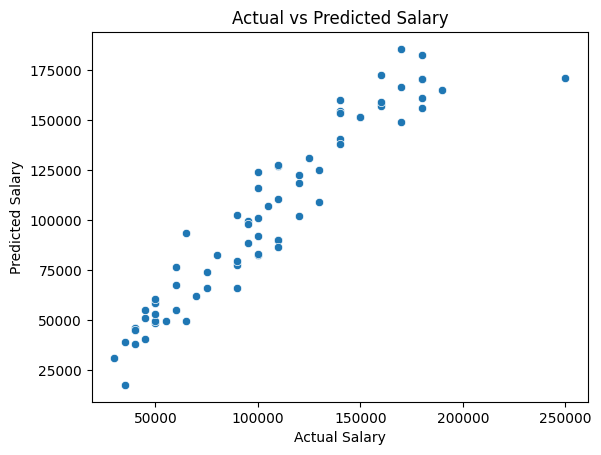

In [39]:
import seaborn as sns
sns.scatterplot(x=y_test,y=y_pred)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()



In [40]:
from sklearn.linear_model import Ridge
ridge_regressor=Ridge()
ridge_regressor.fit(X_train_scaled,y_train)

Ridge()

In [41]:
y_pred=ridge_regressor.predict(X_test_scaled)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [42]:
print("Mean Squared Error:",mse)
print("R-squared:",r2)

Mean Squared Error: 231018889.8025199
R-squared: 0.9036450605692272


In [43]:
from sklearn.linear_model import RidgeCV
ridge_regressor=RidgeCV()
ridge_regressor.fit(X_train_scaled,y_train)

RidgeCV()

In [44]:
y_pred=ridge_regressor.predict(X_test_scaled)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [45]:
print("Mean Squared Error:",mse)
print("R-squared:",r2)

Mean Squared Error: 228440136.76740548
R-squared: 0.9047206245316277


In [46]:
from sklearn.linear_model import ElasticNetCV
elastic_regressor=ElasticNetCV()
elastic_regressor.fit(X_train_scaled,y_train)

ElasticNetCV()

In [47]:
y_pred=_regressor.predict(X_test_scaled)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [48]:
print("Mean Squared Error:",mse)
print("R-squared:",r2)

Mean Squared Error: 2188631602.183652
R-squared: 0.08715055446353048


In [49]:
print("Best model is RidgeCV")

Best model is RidgeCV


In [50]:
ridge_regressor=RidgeCV()
ridge_regressor.fit(X_train_scaled,y_train)

RidgeCV()

In [53]:
y_pred_ridge=ridge_regressor.predict(X_test_scaled)

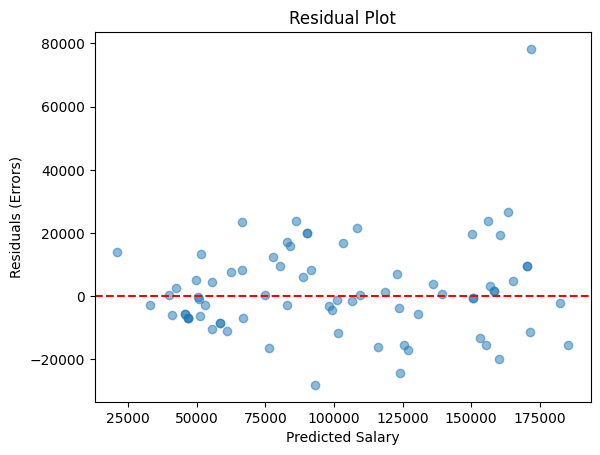

In [54]:
residuals = y_test - y_pred_ridge
plt.scatter(y_pred_ridge, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Errors)')
plt.title('Residual Plot')
plt.show()